In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
df = pd.read_csv('data/superstore_sales.csv')
print(df.head())
print('\n数据形状:', df.shape)
print('\n数据类型:')
print(df.dtypes)
print('\n缺失值统计:')
print(df.isnull().sum())

    order_id  order_date   ship_date customer_id customer_name segment region  \
0  ORD-54527  2025-05-17  2025-05-21       C0227       客户_0320     消费者     东北   
1  ORD-38360  2025-03-31  2025-04-04       C0308       客户_0207     消费者     华东   
2  ORD-31795  2025-05-16  2025-05-18       C0089       客户_0217     消费者    NaN   
3  ORD-33820  2025-09-30  2025-10-07       C0098       客户_0238     消费者     华南   
4  ORD-31077  2025-12-12  2025-12-18       C0774       客户_0161    小型办公     华中   

  city category sub_category    sales  quantity  discount  profit  
0  哈尔滨       家具           书架   997.67         5      0.00  221.80  
1   上海     办公用品            笔    46.74        10      0.00   13.98  
2   长春       家具          文件柜  1089.37         2      0.10   89.19  
3   深圳       家具          文件柜  4747.98         8      0.15  637.89  
4   武汉     电子设备          充电器   486.45         9      0.05  -19.66  

数据形状: (15150, 14)

数据类型:
order_id          object
order_date        object
ship_date         object
cust

In [2]:
# 处理重复行
print(df.duplicated().sum())
df = df.drop_duplicates()
print(df.duplicated().sum())


150
0


In [3]:
# 处理缺失值
print('各列缺失值数量:')
print(df.isnull().sum())
print('\n缺失值比例:')
print((df.isnull().sum() / len(df) * 100).round(2))
df.loc[:, "segment"] = df["segment"].fillna(df["segment"].mode()[0])
df.loc[:, "region"] = df["region"].fillna(df["region"].mode()[0])
df.loc[:,"sales"] = df["sales"].fillna(df["sales"].median())
df.loc[:, "profit"] = df["profit"].fillna(df["profit"].median())
print(df.isnull().sum())


各列缺失值数量:
order_id           0
order_date         0
ship_date          0
customer_id        0
customer_name      0
segment          304
region           297
city               0
category           0
sub_category       0
sales            301
quantity           0
discount           0
profit           305
dtype: int64

缺失值比例:
order_id         0.00
order_date       0.00
ship_date        0.00
customer_id      0.00
customer_name    0.00
segment          2.03
region           1.98
city             0.00
category         0.00
sub_category     0.00
sales            2.01
quantity         0.00
discount         0.00
profit           2.03
dtype: float64
order_id         0
order_date       0
ship_date        0
customer_id      0
customer_name    0
segment          0
region           0
city             0
category         0
sub_category     0
sales            0
quantity         0
discount         0
profit           0
dtype: int64


In [4]:
# 处理异常值(IQR)
q1 = df["sales"].quantile(0.25)
q3 = df["sales"].quantile(0.75)
iqr = q3-q1
lower = q1-1.5*iqr
upper = q3+1.5*iqr
print(lower)
print(upper)
print(f'异常值数量: {((df["sales"] < lower) | (df["sales"] > upper)).sum()}')
outer = df[(df["sales"]<lower)|(df["sales"]>upper)]
print(outer)


-6455.643750000001
11113.306250000001
异常值数量: 2125
        order_id  order_date   ship_date customer_id customer_name segment  \
6      ORD-74270  2025-08-06  2025-08-10       C0194       客户_0555     消费者   
9      ORD-24590  2025-02-04  2025-02-11       C0128       客户_0532    小型办公   
12     ORD-98468  2025-01-28  2025-01-31       C0140       客户_0679      企业   
13     ORD-94248  2025-02-20  2025-02-21       C0077       客户_0429      企业   
29     ORD-95538  2025-12-10  2025-12-17       C0688       客户_0008    小型办公   
...          ...         ...         ...         ...           ...     ...   
15109  ORD-28855  2025-01-27  2025-01-29       C0548       客户_0659     消费者   
15110  ORD-52059  2025-12-13  2025-12-19       C0551       客户_0336      企业   
15123  ORD-22659  2025-06-05  2025-06-06       C0254       客户_0099     消费者   
15128  ORD-56924  2025-04-17  2025-04-19       C0299       客户_0245     消费者   
15132  ORD-97664  2025-04-08  2025-04-09       C0697       客户_0354    小型办公   

      region 

In [5]:
# 处理异常值(盖帽法)
df.loc[:, "sales"] = df["sales"].clip(lower,upper)
print('处理后销售额描述:')
print(df['sales'].describe())

处理后销售额描述:
count    15000.000000
mean      3086.466568
std       3906.907360
min          0.043931
25%        132.712500
50%       1181.690000
75%       4524.950000
max      11113.306250
Name: sales, dtype: float64


In [6]:
# 日期类型转换
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["ship_date"]  = pd.to_datetime(df["ship_date"],  errors="coerce")
print(df["order_date"].dtypes)
print(df["ship_date"].dtypes)
df.loc[: ,"month"] = df["order_date"].dt.month
df.loc[: ,"quarter"] = df["order_date"].dt.quarter
df.loc[: ,"weekday"] = df["order_date"].dt.dayofweek + 1
df = df.assign(ship_days = (df["ship_date"] - df["order_date"]).dt.days)
print(df[['order_date', 'ship_date', 'ship_days', 'month', 'quarter']].head())

datetime64[ns]
datetime64[ns]
  order_date  ship_date  ship_days  month  quarter
0 2025-05-17 2025-05-21          4      5        2
1 2025-03-31 2025-04-04          4      3        1
2 2025-05-16 2025-05-18          2      5        2
3 2025-09-30 2025-10-07          7      9        3
4 2025-12-12 2025-12-18          6     12        4


清洗后数据形状: (15000, 18)

数值列描述统计:
              sales        profit      quantity      discount     ship_days
count  15000.000000  15000.000000  15000.000000  15000.000000  15000.000000
mean    3086.466568    675.780660      5.511667      0.066890      4.023067
std     3906.907360   2079.208696      2.895748      0.088625      1.997232
min        0.043931  -8144.100000      1.000000      0.000000      1.000000
25%      132.712500     15.500000      3.000000      0.000000      2.000000
50%     1181.690000    105.230000      6.000000      0.050000      4.000000
75%     4524.950000    515.192500      8.000000      0.100000      6.000000
max    11113.306250  29749.000000     10.000000      0.300000      7.000000
    order_id order_date  ship_date customer_id customer_name segment region  \
0  ORD-54527 2025-05-17 2025-05-21       C0227       客户_0320     消费者     东北   
1  ORD-38360 2025-03-31 2025-04-04       C0308       客户_0207     消费者     华东   
2  ORD-31795 2025-05-16 2025-05-18       C0089  

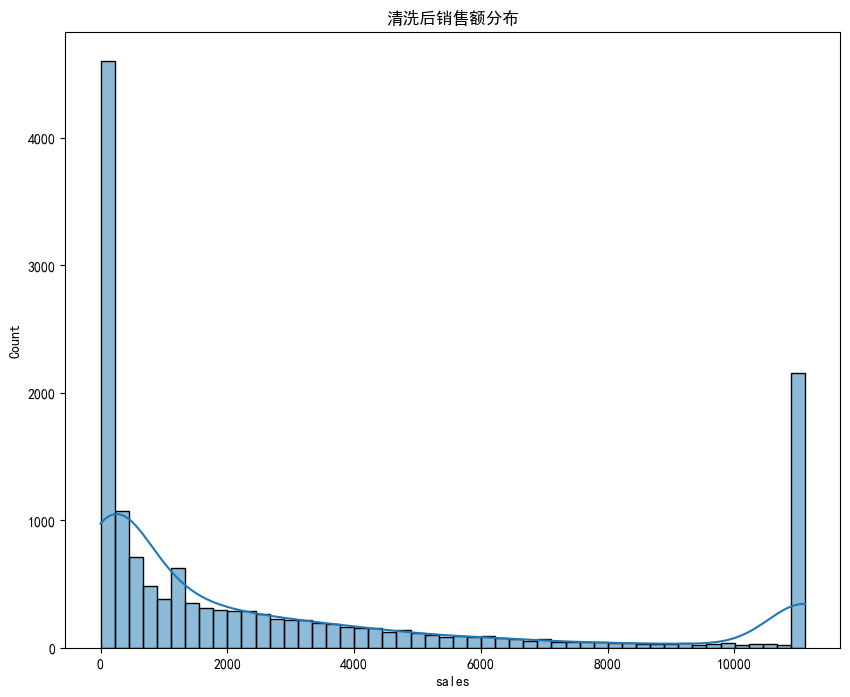

In [7]:
# 清洗后数据探索
print('清洗后数据形状:', df.shape)
print('\n数值列描述统计:')
print(df[['sales', 'profit', 'quantity', 'discount', 'ship_days']].describe())
print(df.head(3))
plt.figure(figsize=(10,8))
sns.histplot(data=df,x="sales",bins=50,kde=True)
plt.title("清洗后销售额分布")
plt.show()
df.to_excel("双算_project4.xlsx", index=False)

0    0.210815
1    0.221028
2    0.230078
3    0.202268
4    0.229978
5    0.221740
Name: profit_rate, dtype: float64
  region     sales_sum  profit_sum  id_count  profit_rate
0     东北  7.135391e+06  1504250.35      2356     0.210815
1     华东  7.838667e+06  1732563.37      2510     0.221028
2     华中  7.607873e+06  1750407.07      2438     0.230078
3     华北  8.766590e+06  1773200.39      2810     0.202268
4     华南  7.479447e+06  1720107.48      2441     0.229978
5     西部  7.469030e+06  1656181.24      2445     0.221740


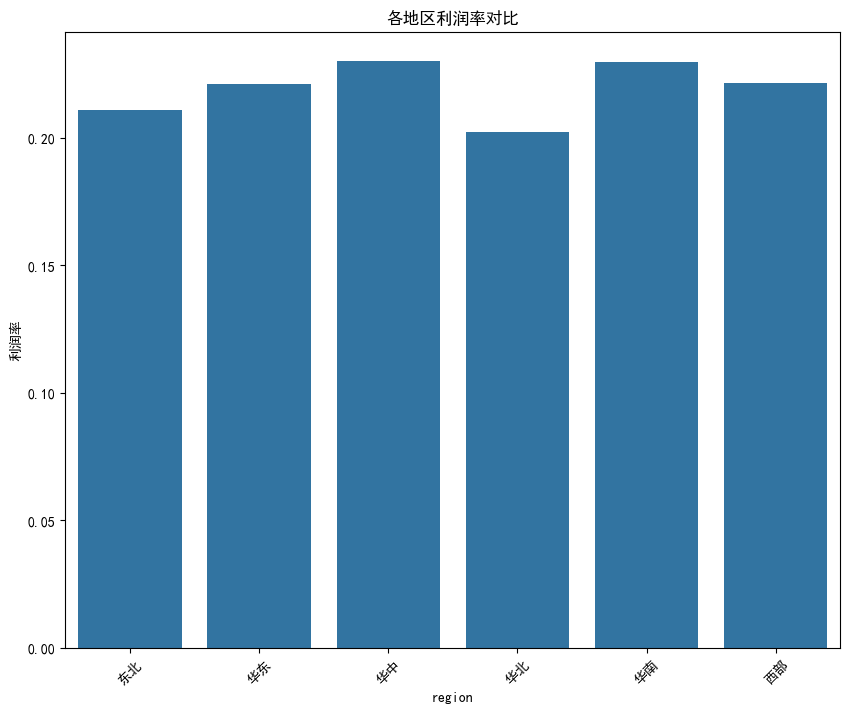

In [8]:
# 哪个地区销售额最高？哪个利润率最好？
r_stats = df.groupby("region").agg(sales_sum=("sales","sum"),profit_sum=("profit","sum"),id_count=("order_id","count")).reset_index()
r_stats["profit_rate"] = r_stats["profit_sum"] / r_stats["sales_sum"]
print(r_stats["profit_rate"])
print(r_stats)
plt.figure(figsize=(10,8))
sns.barplot(data=r_stats,x="region",y="profit_rate")
plt.title("各地区利润率对比")
plt.ylabel("利润率")
plt.xticks(rotation=45)
plt.show()

Empty DataFrame
Columns: [sub_category, s_sales, s_profit]
Index: []


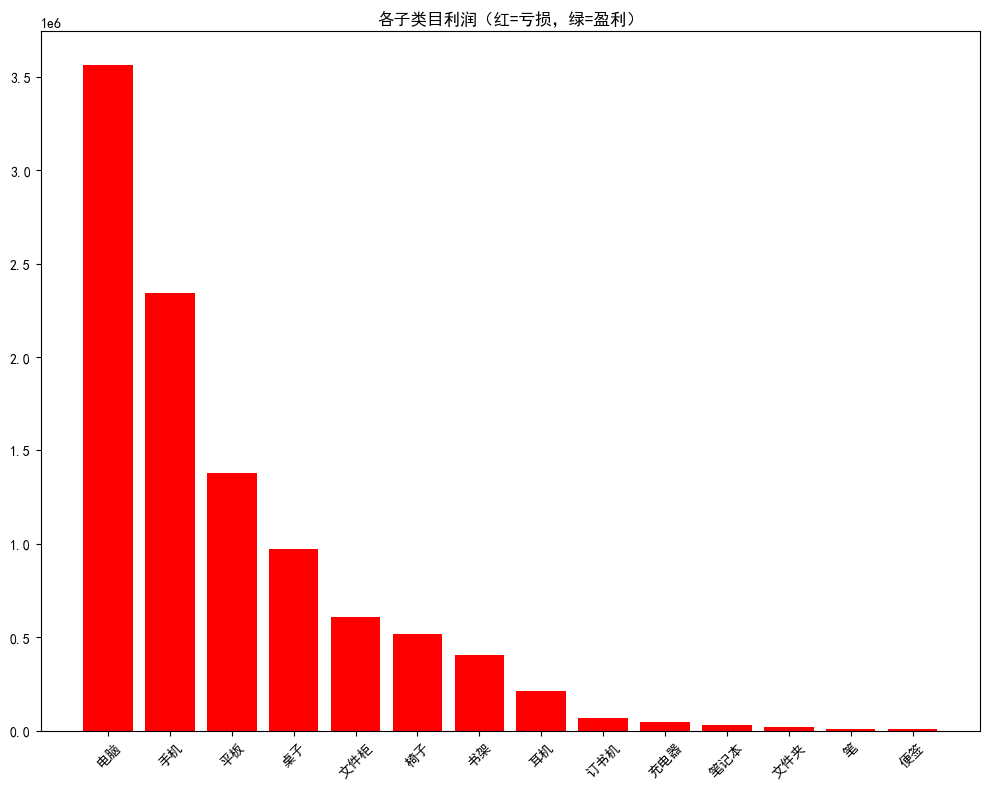

   sub_category       s_sales    s_profit
9            电脑  3.524492e+07  3564923.17
4            手机  2.312489e+07  2340107.77
3            平板  1.458246e+07  1380946.48
7            桌子  5.784779e+06   969529.15
6           文件柜  3.852001e+06   609472.24
8            椅子  3.329296e+06   517870.55
0            书架  2.420207e+06   402811.62
12           耳机  2.231012e+06   211605.03
13          订书机  3.387941e+05    66715.35
2           充电器  4.544839e+05    45434.12
11          笔记本  1.274521e+05    32460.94
5           文件夹  2.182485e+05    20446.74
10            笔  4.297371e+04    10923.05
1            便签  3.982355e+04     9901.83


In [3]:
# 哪个类目最赚钱？哪个子类目亏钱？
cat_max=df.groupby("category").agg(sales_sum=("sales","sum"),profit_sum=("profit","sum")).reset_index()
sub_cat=df.groupby("sub_category").agg(s_sales=("sales","sum"),s_profit=("profit","sum")).reset_index().sort_values("s_profit",ascending=False)
loss = sub_cat[sub_cat["s_profit"]<0]
print(loss)
plt.figure(figsize=(10,8))
colors = ["red" if x > 0 else "green" for x in sub_cat["s_profit"]]
plt.bar(sub_cat["sub_category"],sub_cat["s_profit"],color=colors)
plt.title("各子类目利润（红=亏损，绿=盈利）")
plt.xticks(rotation=45)
plt.axhline(y=0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()
print(sub_cat)

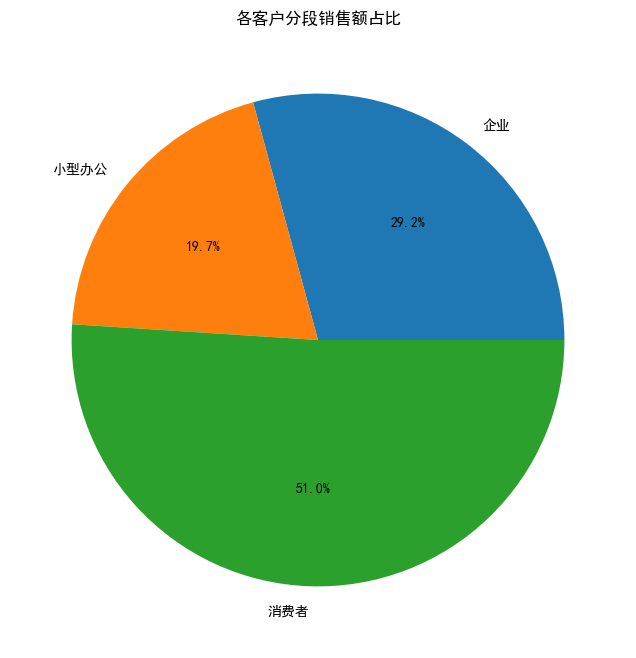

  segment     sales_sum  profit_sum  cus_only     cus_price
0      企业  1.353888e+07  3013856.22       798  16966.017718
1    小型办公  9.138346e+06  2060468.52       788  11596.885222
2     消费者  2.361977e+07  5062385.16       800  29524.713530


In [39]:
# 3种客户分段（消费者/企业/小型办公）哪个价值最高？
seg_stats = df.groupby("segment").agg(sales_sum = ("sales","sum"),profit_sum=("profit","sum"),cus_only = ("customer_id","nunique")).reset_index()
seg_stats["cus_price"] = seg_stats["sales_sum"]/seg_stats["cus_only"]
plt.figure(figsize=(8,8))
plt.pie(seg_stats["sales_sum"], labels=seg_stats["segment"], autopct="%1.1f%%")
plt.title("各客户分段销售额占比")
plt.show()
print(seg_stats)

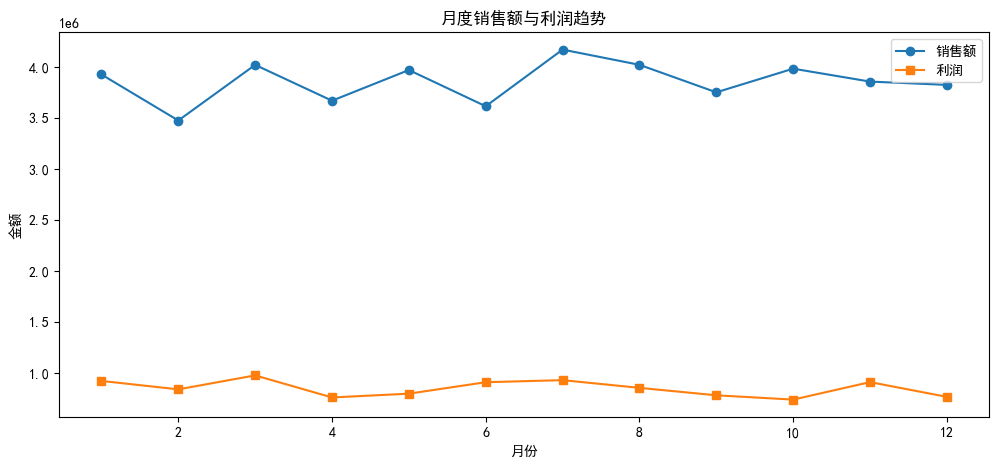

    month     sales_sum  profit_sum  growth_rate
0       1  3.927586e+06   918176.61          NaN
1       2  3.475636e+06   835272.11    -0.115071
2       3  4.021924e+06   972624.32     0.157176
3       4  3.670081e+06   755862.93    -0.087481
4       5  3.971352e+06   792993.09     0.082088
5       6  3.615586e+06   905627.76    -0.089583
6       7  4.171985e+06   925837.35     0.153889
7       8  4.022573e+06   850211.01    -0.035813
8       9  3.752377e+06   777037.51    -0.067170
9      10  3.984686e+06   734823.95     0.061910
10     11  3.857813e+06   906537.39    -0.031840
11     12  3.825400e+06   761705.87    -0.008402


In [11]:
# 哪个月销售最好？季度趋势如何？
month_sales = df.groupby("month").agg(sales_sum = ("sales","sum"),profit_sum=("profit","sum")).reset_index()
plt.figure(figsize=(12, 5))
plt.plot(month_sales["month"], month_sales["sales_sum"], label="销售额", marker="o")
plt.plot(month_sales["month"], month_sales["profit_sum"], label="利润", marker="s")
plt.title("月度销售额与利润趋势")
plt.xlabel("月份")
plt.ylabel("金额")
plt.legend()
plt.show()
quarter_stats = df.groupby("quarter").agg(
    q_sales=("sales", "sum"),
    q_profit=("profit", "sum")
).reset_index()
month_sales["growth_rate"] = month_sales["sales_sum"].pct_change()
print(month_sales)


0.029822812149525972


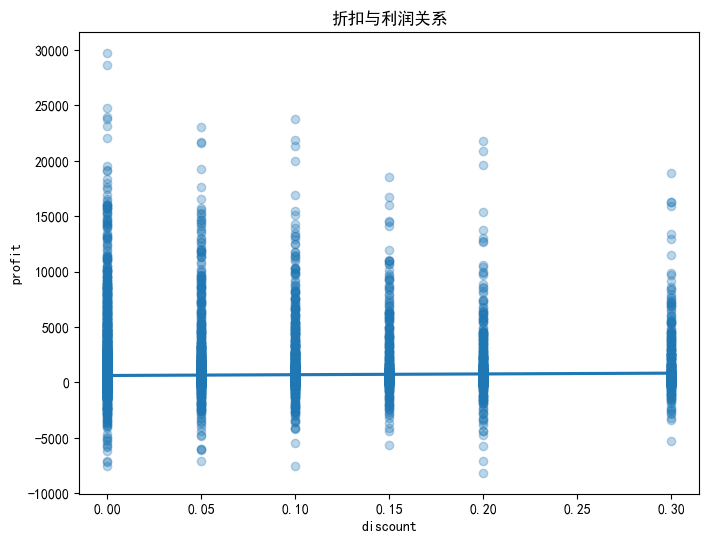

  discount_level  avg_profit  order_count
0          0-10%  764.663124         4372
1         10-20%  762.792144         2192
2         20-30%  770.516355          974
3         30-50%         NaN            0
4           50%+         NaN            0


C:\Users\coo07\AppData\Local\Temp\ipykernel_29140\195901228.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disc_stats = df.groupby("discount_level").agg(


In [12]:
# 利润分析
corr_d = df["discount"].corr(df["profit"])
print(corr_d)
plt.figure(figsize=(8, 6))
sns.regplot(data=df, x="discount", y="profit", scatter_kws={"alpha": 0.3})
plt.title("折扣与利润关系")
plt.show()
df["discount_level"] = pd.cut(df["discount"], bins=[0, 0.1, 0.2, 0.3, 0.5, 1.0], 
                                labels=["0-10%", "10-20%", "20-30%", "30-50%", "50%+"])
disc_stats = df.groupby("discount_level").agg(
    avg_profit=("profit", "mean"),
    order_count=("order_id", "count")
).reset_index()
print(disc_stats)

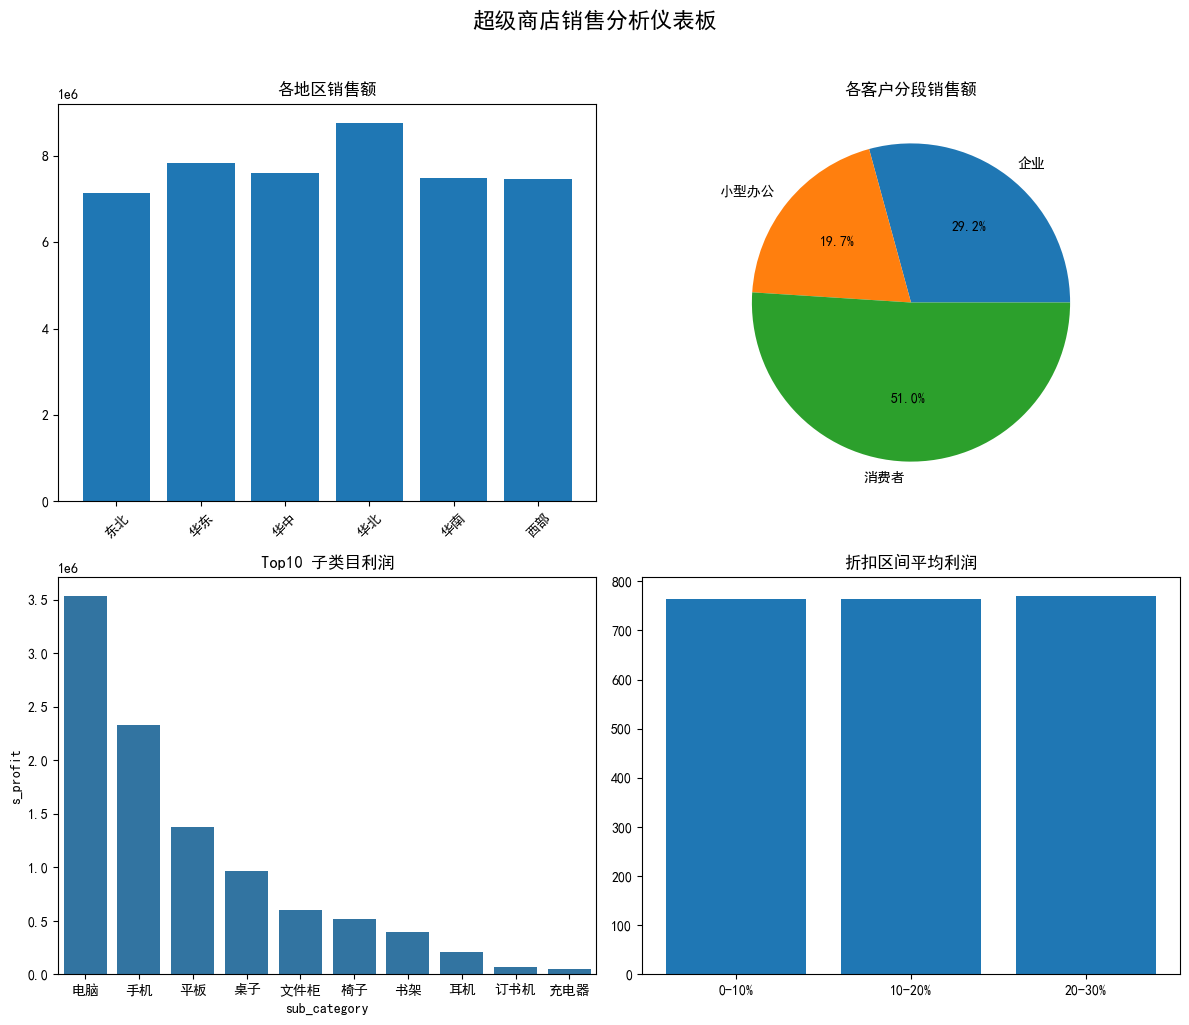

In [26]:
# 综合仪表板
fig,axes = plt.subplots(2,2,figsize=(12,10))
# 左上：各地区销售额（柱状图）
axes[0,0].bar(r_stats["region"],r_stats["sales_sum"])
axes[0,0].set_title("各地区销售额")
axes[0, 0].tick_params(axis="x", rotation=45)
# 右上：各客户分段销售额占比（饼图）
axes[0,1].pie(seg_stats["sales_sum"], labels=seg_stats["segment"], autopct="%1.1f%%")
axes[0,1].set_title("各客户分段销售额")
# 左下：Top10 子类目利润（水平条形图）
top10 = sub_cat.head(10)
sns.barplot(data=top10,x="sub_category",y="s_profit",ax=axes[1,0])
axes[1,0].set_title("Top10 子类目利润")
# 右下：折扣区间平均利润（柱状图）
axes[1,1].bar(disc_stats["discount_level"],disc_stats["avg_profit"])
axes[1,1].set_title("折扣区间平均利润")
plt.suptitle("超级商店销售分析仪表板",fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("charts/dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

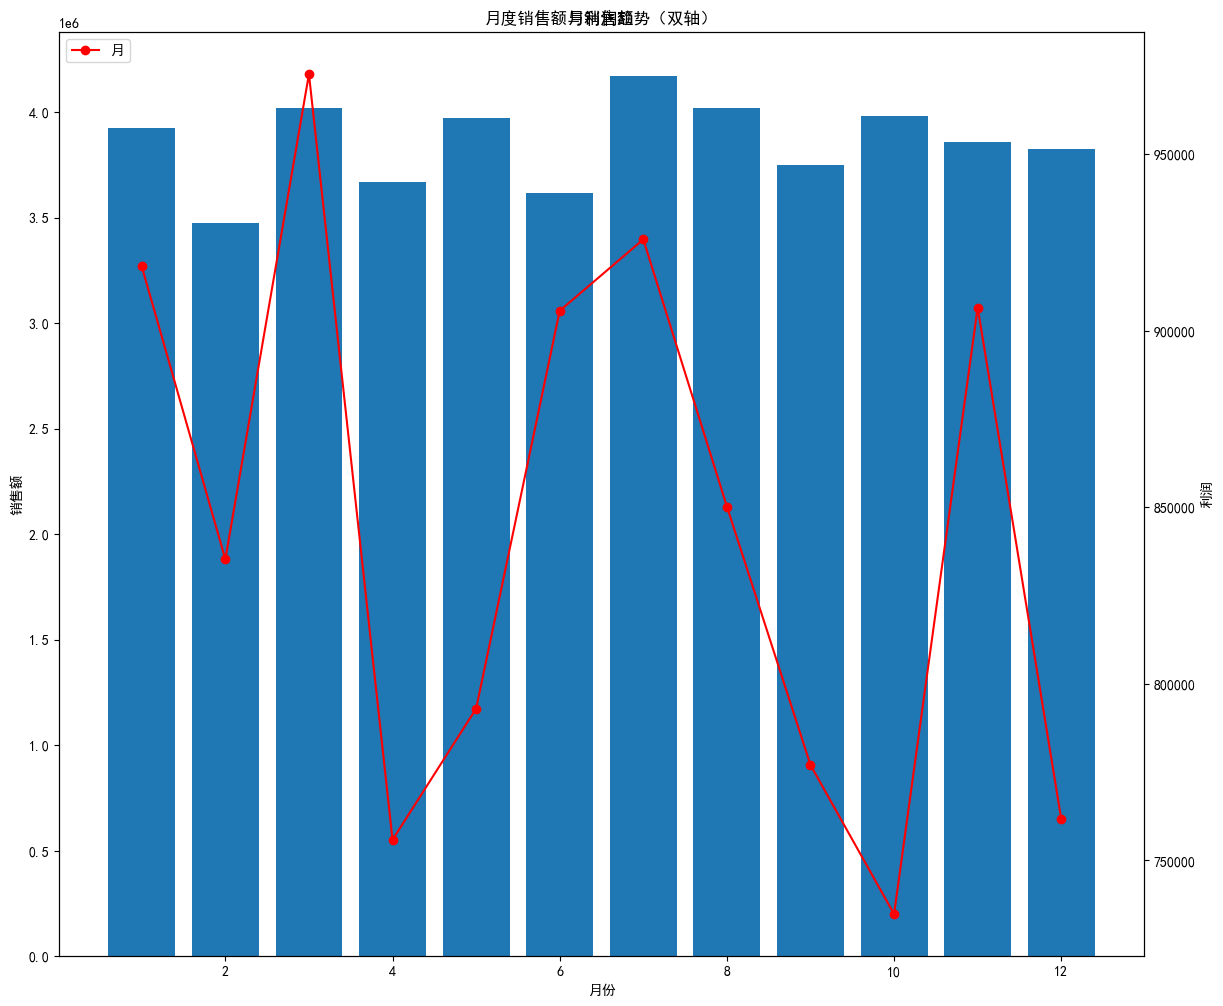

In [36]:
# 月度销售-利润-环比组合图
fig,ax1 = plt.subplots(figsize=(14,12))
# 左 y 轴：柱状图（月销售额）
ax1.bar(month_sales["month"],month_sales["sales_sum"])
ax1.set_title("月销售额")
ax1.set_xlabel("月份")
ax1.set_ylabel("销售额")
ax1.tick_params(axis="y")
# 右 y 轴：折线图（利润 + 环比）
ax2 = ax1.twinx()
ax2.plot(month_sales["month"],month_sales["profit_sum"],color="red",marker="o",label="月")
ax2.set_ylabel("利润")
# 合并图例
lines1,labels1 = ax1.get_legend_handles_labels()
lines2,labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2,labels1+labels2,loc="upper left")
plt.title("月度销售额与利润趋势（双轴）")
plt.savefig("charts/monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()